# Práctica: Construcción de un modelo URDF

## Objetivo

Construir un modelo cinemático del manipulador **SO-100** a partir de las piezas STL proporcionadas, organizarlas y orientarlas en Blender, identificar las transformaciones entre sistemas de referencia y describir la estructura del robot mediante un archivo **URDF**. Finalmente, visualizar y verificar el modelo en VS Code mediante la extensión **URDF Visualizer**.

## Rúbrica de evaluación

### Metas

Que el alumno:

- Haga uso de funciones básicas de Blender
- Obtenga información a partir del modelo STL de un robot
- Visualice las transformaciones entre sistemas de referencia y las distinga de transformaciones de elementos visuales
- Construya un modelo URDF a partir de la información obtenida


### Contribución al perfil del egresado

La siguiente práctica contribuye en los siguientes puntos al perfil del egresado:


#### Aptitudes y habilidades

- Para diseñar, construir, operar y mantener los sistemas mecatrónicos y sus componentes.
- Para crear, innovar o evaluar las tecnologías relacionadas con la mecatrónica.


#### Actitudes profesionales

- Ser creativo e innovador.
- Tener confianza en su preparación académica.
- Comprometido con su actualización, superación y competencia profesional.


#### Actitudes de tipo social

- Promover el cambio en la mentalidad frente a la competitividad internacional.


### La evaluación de la práctica contará de los siguientes puntos

| Elemento | Porcentaje |
| ------:| ----------- |
| **Cuestionario previo** | 15% | 
| **Desarrollo** | 35% |
| **Análisis de resultados**  | 35% |
| **Conclusiones** | 15% |


### Se evaluará con los siguientes criterios:

| Elemento | Malo | Regular | Bueno |
| ------: | ------ | -------- | ------ |
| **Cuestionario previo** | El trabajo no contiene cuestionario previo o todas las preguntas son incorrectas (0%) | Al menos la mitad de las preguntas son correctas (8%) | Todas las preguntas son correctas (15%) |
| **Desarrollo** | El trabajo no contiene desarrollo o su planteamiento no concuerda con lo deseado (0%) | El desarrollo está mal planteado o no llega a los resultados esperados (10%) | El desarrollo tiene un planteamiento adecuado y llega a los resultados esperados (35%) |
| **Análisis de resultados** | El trabajo no contiene análisis de resultados o la información no se está interpretando correctamente (0%) | La interpretación de los resultados es parcial o desorganizada (10%) | Realiza un correcto análisis de los resultados de forma organizada (35%) |
| **Conclusiones** | El trabajo no contiene conclusiones o no hacen referencia al trabajo desarrollado y los objetivos planteados (0%) | La redacción de las conclusiones es desorganizada o confusa (8%) | Las conclusiones del trabajo son claras y hacen referencia al trabajo desarrollado y los objetivos planteados (15%) |


## Introducción

### Modelo geométrico y cinemático de un robot

Para describir un robot manipulador en ROS, se utiliza con frecuencia el formato **URDF (Unified Robot Description Format)**. Un archivo URDF es un documento XML que representa el robot como un conjunto de **eslabones** (*links*) conectados mediante **articulaciones** (*joints*). Cada eslabón puede incluir geometría visual, geometría de colisión y propiedades inerciales; cada junta define cómo se conecta un eslabón hijo con uno padre, el tipo de movimiento permitido y la pose relativa entre ambos sistemas de referencia.

Los tipos de junta más comunes son `fixed` (sin movimiento relativo), `revolute` (rotación limitada alrededor de un eje), `continuous` (rotación sin límites angulares) y `prismatic` (traslación). En un manipulador como el SO-100, las articulaciones de los motores se representan normalmente como articulaciones rotacionales. La etiqueta `origin` expresa la transformación entre los marcos de la junta padre e hijo mediante `xyz` (traslación) y `rpy` (orientación en ángulos roll, pitch y yaw, en radianes). El eje de movimiento se especifica mediante `axis`; por convención, se expresa en el marco de la junta.

Una descripción URDF no se obtiene únicamente colocando las mallas STL una junto a otra: es necesario determinar correctamente la relación entre los sistemas de referencia. Un error en la orientación de una junta puede hacer que el modelo se vea razonablemente bien, pero que el robot rote alrededor de un eje incorrecto. Por ello, en esta práctica se utilizará Blender para inspeccionar y preparar las piezas y, posteriormente, se describirán las transformaciones en URDF.

### Manejo básico de Blender para preparar piezas robóticas

**Blender** es una herramienta de modelado 3D que permite importar mallas STL, inspeccionar su geometría, transformar objetos y establecer jerarquías padre/hijo. Cada objeto tiene un sistema de referencia local (origen del objeto y ejes locales X, Y y Z), distinto del sistema de coordenadas global de la escena. Para esta práctica, los sistemas locales deben facilitar la interpretación cinemática: el eje **Z local de cada pieza asociada a un motor debe alinearse con el eje de giro de ese motor**.

Las transformaciones de un objeto incluyen ubicación, rotación y escala. En Blender, **Apply Rotation** aplica la rotación actual a los datos de la malla y deja los valores de rotación del objeto en cero, conservando su apariencia en la escena. Esto resulta útil para preparar una geometría cuya orientación debe quedar incorporada en la malla, aunque debe hacerse deliberadamente: aplicar una rotación cambia cómo se interpretan las coordenadas locales de la geometría y puede afectar las transformaciones que luego se documenten en URDF.

En esta práctica, Blender se utilizará para construir un archivo de inspección y organización de las piezas, no para sustituir la definición cinemática del URDF. El modelo final deberá tener una jerarquía coherente y los marcos de referencia necesarios para calcular `origin xyz`, `origin rpy` y `axis`.

## Cuestionario previo

1. ¿Cuál es la diferencia entre un `link` y un `joint` en URDF?
> Un link representa una parte física del robot, como la base o un brazo, mientras que un joint conecta dos eslabones y define cómo pueden moverse entre sí.

2. ¿Qué información se define en las etiquetas `origin`, `axis` y `parent`/`child` de una junta URDF?
> origin define la posición y orientación de la articulación, axis indica el eje sobre el que se mueve y parent/child identifican el eslabón padre y el eslabón hijo que conecta.

3. ¿Cuál es la diferencia entre el sistema de coordenadas global y el sistema local de un objeto en Blender?
> El sistema global es una referencia fija para toda la escena, mientras que el sistema local pertenece a cada objeto y cambia su orientación cuando el objeto gira.

4. ¿Qué hace la operación **Apply Rotation** en blender?
> Aplica la rotación actual a la geometría del objeto, dejando sus valores de rotación en cero sin cambiar su orientación visual.
5. ¿En qué unidades se especifican las traslaciones y los ángulos en URDF?
> Las traslaciones se especifican en metros (m) y los ángulos en radianes (rad).

## Desarrollo

### 1. Preparación del espacio de trabajo

1. Dentro de la carpeta de la práctica, cree carpetas con la siguiente estructura. Guarde en `meshes/` los STL proporcionados y conserve los nombres de archivo originales cuando sea posible.

```text
practica_2/
├── blender/
│   └── so100_modelo.blend
├── meshes/
│   ├── base.stl
│   └── ... (resto de las piezas proporcionadas)
├── urdf/
│   └── so100.urdf
└── imagenes/
    ├── blender_jerarquia.png
    ├── blender_ejes.png
    ├── ...
    └── urdf_visualizer.png
```

2. Abra Blender y guarde el proyecto como `blender/so100_modelo.blend`.
3. Elimine los objetos iniciales que no vaya a utilizar.
4. Importe los archivos STL mediante **File → Import → STL** ó arrastrándolos hacia el editor de blender desde el explorador de archivos.


**Evidencia:** captura de la escena con todas las piezas importadas y nombres legibles.

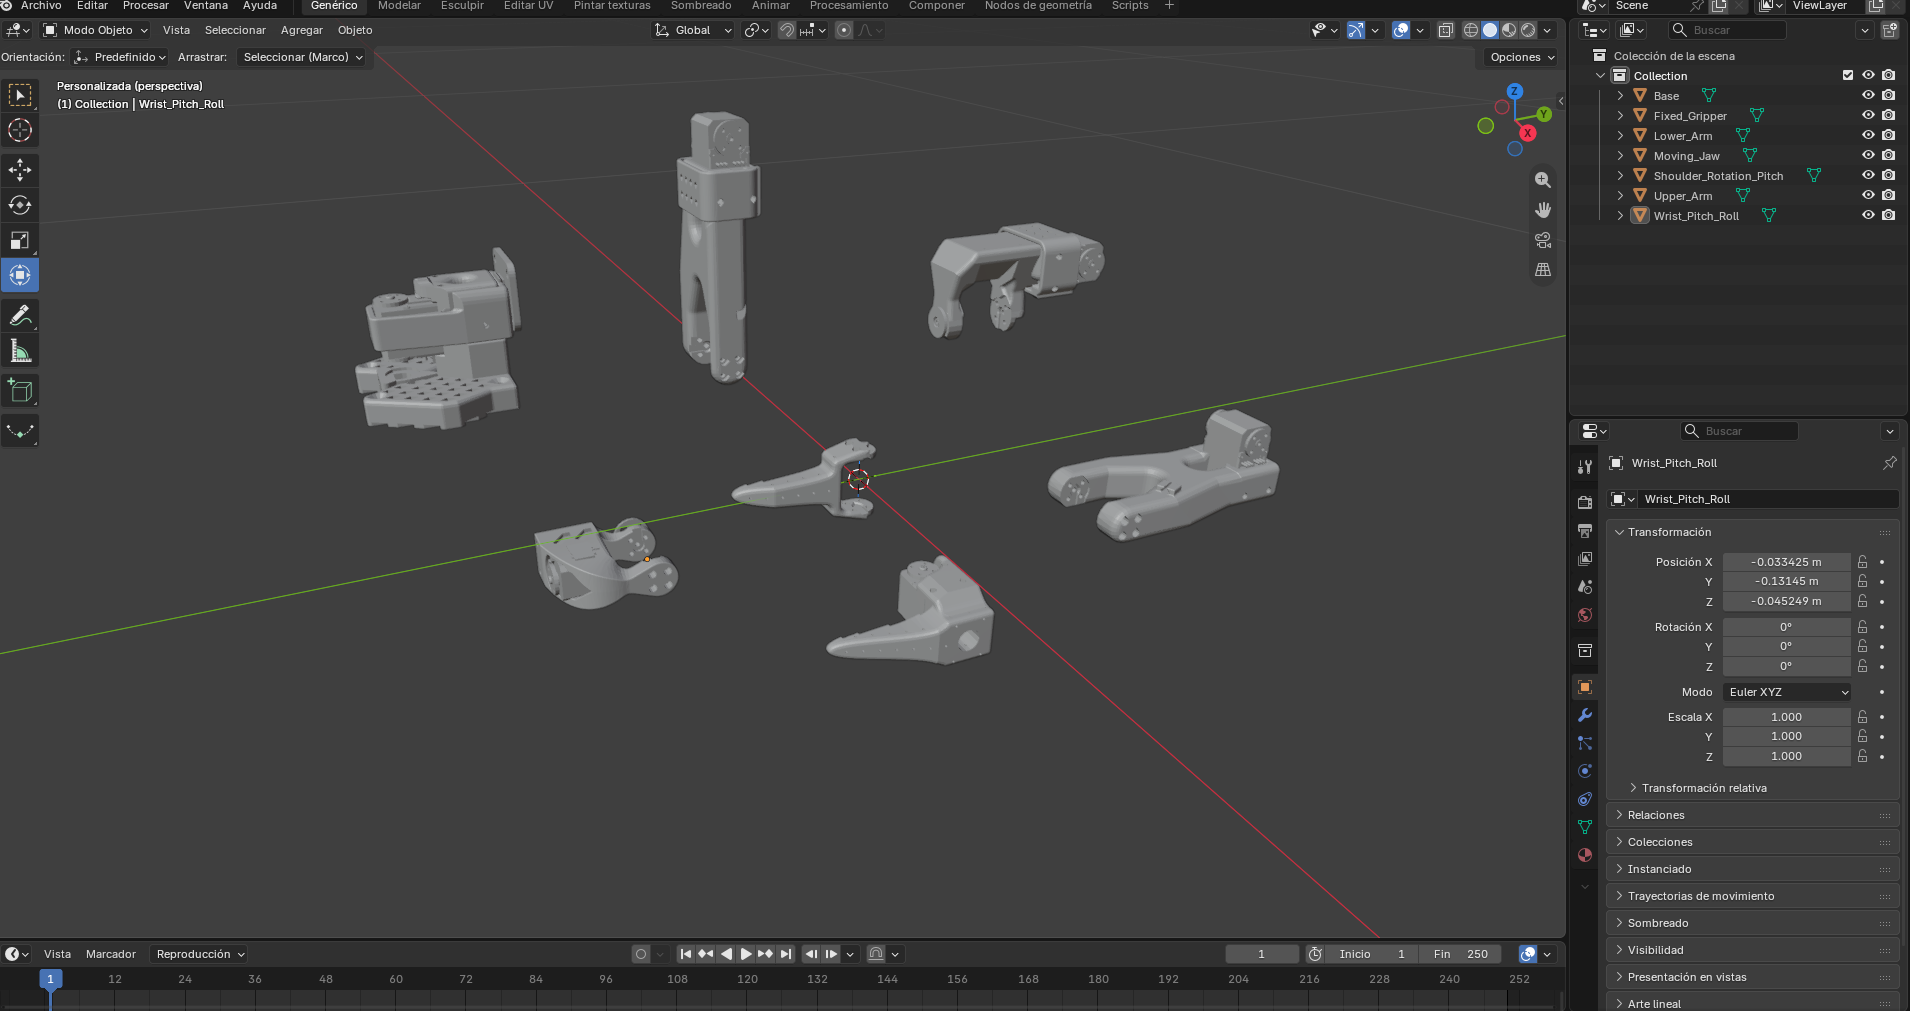

### 2. Mostrar e inspeccionar los sistemas de referencia locales en Blender

1. Para visualizar los sistemas de referencia locales de cada pieza, abrir el menú deplegable de la parte superior derecha **"Viewport Gizmos"** y en la sección "**Object Gizmos**" habilitar *"Move"* y seleccionar en sistemas de referencia *"Local"*

<img src="imagenes/p2_1.png" align="center" alt="Viewport Gizmos" height="500"/>

2. En el menú **"Viewport Overlays"** habilite el eje *"z"* y ajuste la escala de la malla que representa al suelo a **0.001 [m]** (**1 mm**)

<img src="imagenes/p2_2.png" align="center" alt="Viewport Gizmos" height="500"/>

3. Seleccione cada pieza y observe dónde está su origen local y cómo están orientados sus ejes. Registre los resultados en una tabla.

| Pieza / eslabón | Corrección necesaria del eje Z |
|---|---|
| Base | Sin corrección (0°). |
| Hombro | Rotación de +90° sobre el eje X. |
| Brazo superior | Rotación de +90° sobre el eje Y. |
| Brazo inferior | Rotación de +90° sobre el eje Y. |
| Muñeca | Rotación de +90° sobre el eje Y. |
| Pinza fija | Rotación de +90° sobre el eje X. |
| Pinza móvil | Sin corrección (0°). |

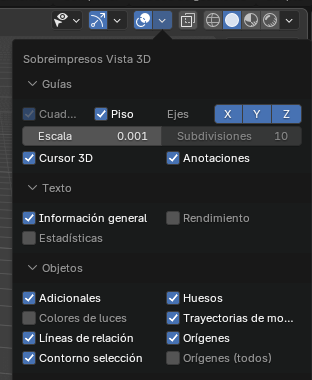

### 3. Orientar las piezas

La jerarquía en Blender sirve para organizar la escena; por sí sola no define el tipo de junta ni sustituye las transformaciones del URDF.

1. Rote la pieza hasta que el eje Z local asociado al motor coincida con el eje físico de giro. Puede utilizar `R` seguido del eje global o local y un ángulo, o introducir valores numéricos en el panel `N`. Confirme visualmente la alineación desde más de una vista.
4. Si se requiere que la orientación quede incorporada en la geometría, use **Object → Apply → Rotation** (`Ctrl+A` → **Rotation**) solo después de verificar el resultado. La rotación del objeto quedará en cero, pero la malla conservará la orientación visual. No aplique transformaciones de manera indiscriminada: registre qué piezas se modificaron y qué efecto tuvo en los ejes locales.
5. Repita el proceso para las piezas restantes. El eje Z del marco asociado a cada motor debe quedar alineado con el eje de giro correspondiente.
6. Guarde el archivo `.blend`.

**Importante:** no confunda “hacer que la malla se vea alineada” con “definir correctamente el marco de junta”. Para el URDF, además de la orientación de la malla visual, deben definirse de forma explícita el origen y el eje de cada junta. La geometría visual de un eslabón puede requerir una transformación propia respecto al marco del eslabón.

**Evidencias:** captura de una pieza con el eje *"z"* alineado con el eje del motor.

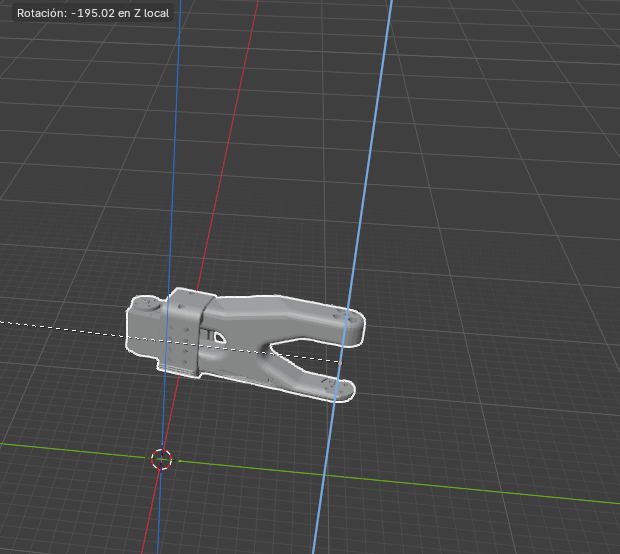

### 3. Crear relaciones padre/hijo y obtener las transformaciones entre sistemas de referencia

La jerarquía en Blender sirve para organizar la escena; por sí sola no define el tipo de junta ni sustituye las transformaciones del URDF.

1. Determine la secuencia mecánica desde la base hasta el efector final. Para cada conexión, identifique cuál pieza será el padre y cuál el hijo.
2. Para establecer una relación padre/hijo, seleccione primero el objeto hijo, después el padre y presione `Ctrl+P`. Elija **Object (Keep Transform)** para conservar la posición y orientación actuales. Verifique la jerarquía en el *Outliner*. Si la opción o el resultado difieren según la versión, consulte el menú **Object → Parent**.

A partir del modelo preparado, determine para cada junta la transformación del marco padre al marco de la junta/hijo. Registre las traslaciones en metros y las orientaciones en radianes.

Una transformación homogénea se expresa como:
$$

{}^{j}\mathbf{T}_{i}=
\begin{bmatrix}
{}^{j}\mathbf{R}_{i} & {}^{j}\mathbf{p}_{i}\\
\mathbf{0}^{T} & 1
\end{bmatrix}

$$

donde \(P\) representa el marco padre, \(J\) el marco de la junta, \({}^{P}\mathbf{p}_{J}=[x\;y\;z]^T\) es la posición del origen de \(J\) respecto a \(P\), y \({}^{P}\mathbf{R}_{J}\) describe la orientación relativa.

Para cada conexión:

3. Identifique el centro del eje de giro del motor en la pieza padre.
4. Identifique la orientación que debe tener el marco de junta para que su eje Z coincida con el eje del motor.
5. Determine la posición relativa entre el origen del marco padre y el origen de la junta.
6. Exprese la orientación relativa mediante ángulos `roll`, `pitch`, `yaw` (en ese orden y en radianes para el atributo URDF `rpy`). No copie directamente los valores Euler de Blender sin verificar que representan la orientación relativa entre los marcos elegidos.
7. Si el origen del STL está desplazado del eje del motor, calcule la transformación necesaria para ubicar la geometría visual respecto al marco del eslabón. Esta transformación puede ser distinta de la transformación de la junta.

Complete la tabla siguiente. Use una fila por junta y añada filas para todas las articulaciones del SO-100 suministrado.


| Junta | Padre | Hijo | Tipo | origin xyz (m) | origin rpy (rad) | axis |
|---|---|---|---|---|---|---|
| shoulder_joint | Base | Shoulder_Rotation_Pitch | revolute | 0 -0.045 0.016 | 0 0 0 | 0 0 1 |
| upper_arm_joint | Shoulder_Rotation_Pitch | Upper_Arm | revolute | 0 -0.0306 0.1025 | 0 -1.57079633 0 | 0 0 1 |
| elbow_joint | Upper_Arm | Lower_Arm | revolute | 0.028 0.11257 0 | 0 0 0 | 0 0 1 |
| wrist_pitch_joint | Lower_Arm | Wrist_Pitch_Roll | revolute | 0.1349 0.0052 0 | 0 0 0 | 0 0 1 |
| wrist_roll_joint | Wrist_Pitch_Roll | Fixed_Gripper | revolute | 0.00055 -0.0601 0.001088 | -1.57079633 1.57079633 0 | 0 0 1 |
| gripper_joint | Fixed_Gripper | Moving_Jaw | revolute | -0.020292 -0.0001 -0.024312 | 1.57079633 0 3.14159265 | 0 0 1 |



**Evidencias:** captura del *Outliner* con las jerarquías padre/hijo y el modelo del robot construído en blender

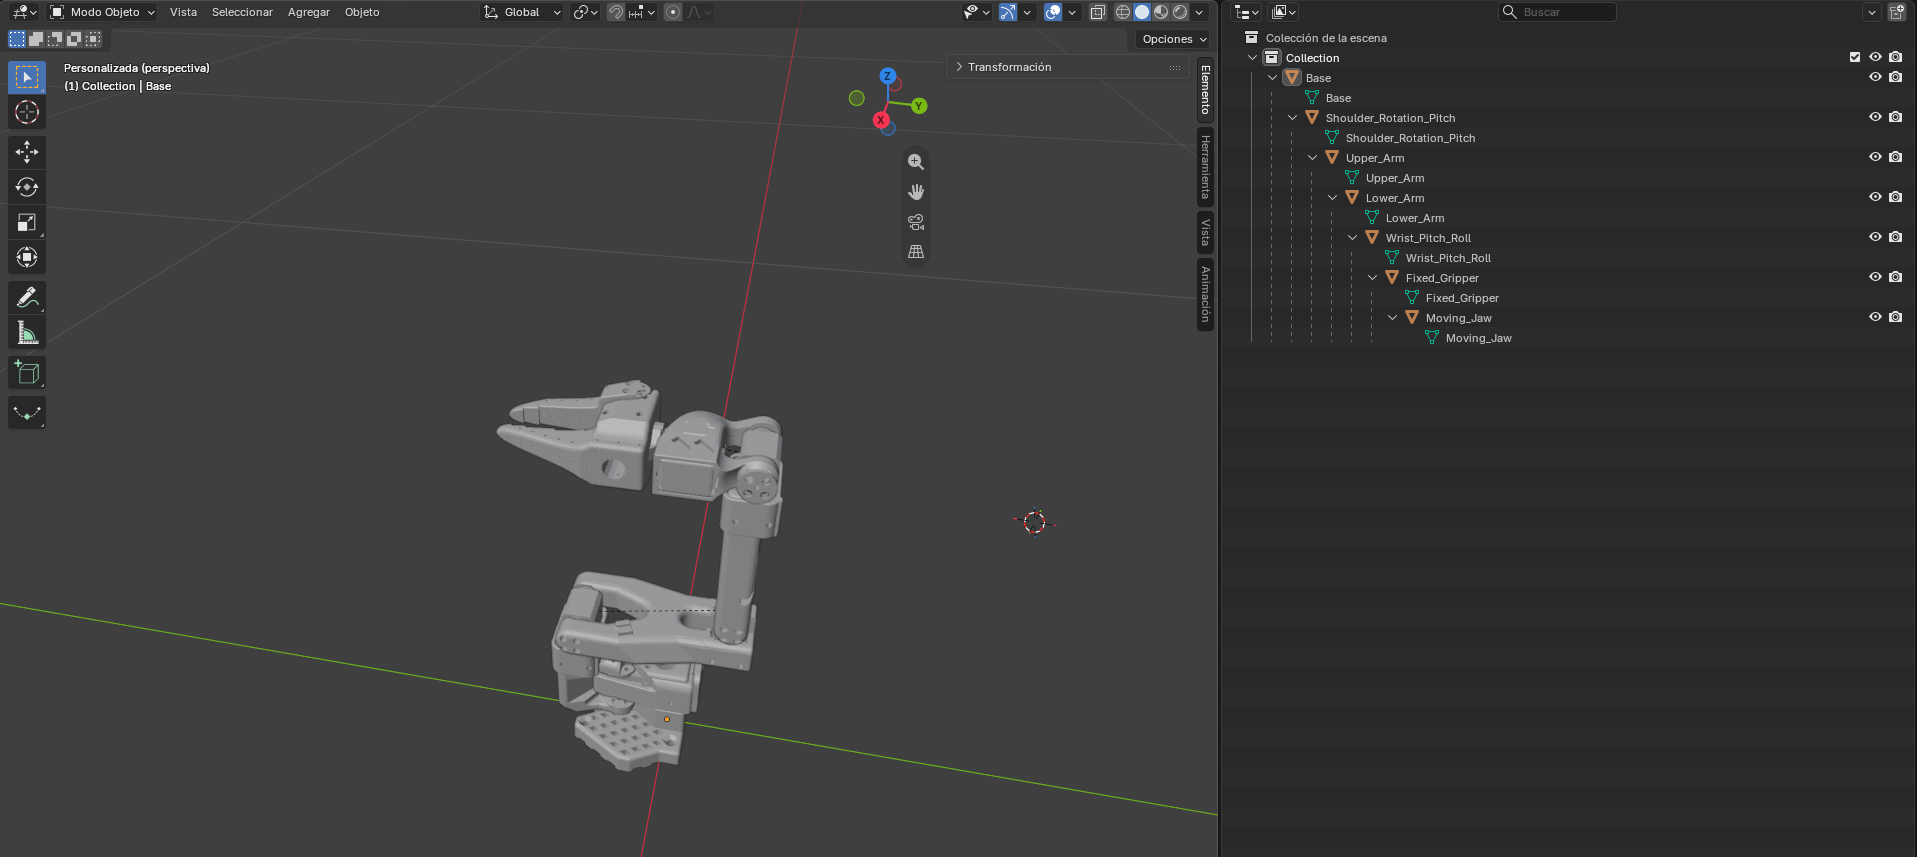

### 5. Construir el archivo URDF en Visual Studio Code

1. Abra en VS Code la carpeta `construccion_urdf/`.
2. Cree `urdf/so100.urdf`.
3. Declare el robot con una etiqueta raíz `<robot name="so100">`.
4. Defina un `<link>` por cada eslabón físico. Incluya una etiqueta `<visual>` con `<geometry><mesh filename="..."/></geometry>`. Use rutas relativas al archivo URDF, por ejemplo `filename="../meshes/base.stl"`; compruebe que el visualizador resuelva correctamente las rutas. Si la extensión requiere una organización distinta, ajuste las rutas y documente el cambio. Para el nombre de las etiquetas de eslabón, puede usar los nombres de los archivos stl
5. Para cada unión entre eslabones, cree una etiqueta `<joint>` con `name`, `type`, `parent`, `child`, `origin` y `axis`. Añada `limit` para articulaciones `revolute`.
6. Defina la junta raíz con el marco de la base y conecte todas las piezas hasta el gripper. Cada eslabón hijo debe conectarse mediante una junta, y cada eslabón debe tener una única conexión padre dentro del árbol cinemático.
7. Incluya una geometría visual por pieza STL. Si el origen local de la malla no coincide con el marco del eslabón, utilice los atributos `origin xyz` y `origin rpy` dentro de `<visual>` para posicionar la malla, sin confundirlos con los de `<joint>`.
8. Para los archivos STL, revise si las unidades de origen son milímetros. URDF interpreta las coordenadas de `origin xyz` en metros; además, verifique que la escala de las mallas importadas sea coherente. No compense un error de escala con traslaciones.
9. Mantenga el XML bien formado: todas las etiquetas deben cerrarse y los nombres de los `link` usados en `parent` y `child` deben existir.

El siguiente fragmento es únicamente una plantilla de estructura; deberá completar las rutas, transformaciones y parámetros del robot real:

```xml
<?xml version="1.0"?>
<robot name="so100">
  <link name="base">
    <visual>
      <origin xyz="0 0 0" rpy="0 0 0"/>
      <geometry>
        <mesh filename="../meshes/base.stl"/>
      </geometry>
    </visual>
  </link>

  <link name="shoulder">
    <visual>
      <origin xyz="0 0 0" rpy="0 0 0"/>
      <geometry>
        <mesh filename="../meshes/shoulder.stl"/>
      </geometry>
    </visual>
  </link>

  <joint name="joint_1" type="revolute">
    <parent link="base"/>
    <child link="shoulder"/>
    <origin xyz="0 0 0" rpy="0 0 0"/>
    <axis xyz="0 0 1"/>
    <limit lower="-1.0" upper="1.0" effort="10" velocity="1.0"/>
  </joint>
</robot>
```

Los valores del fragmento son ilustrativos y **no son dimensiones ni límites reales del SO-100**. Sustitúyalos por los valores calculados o documentados. El ejemplo muestra la estructura de las etiquetas, no un modelo completo funcional.

### 6. Visualizar y validar el URDF con URDF Visualizer

4. Compruebe en el visualizador de URDF en VSCode: 
   - Todas las piezas aparecen y tienen una escala razonable.
   - La base está en una posición coherente.
   - Las piezas están conectadas en el orden cinemático correcto.
   - Los ejes de las articulaciones coinciden con los ejes de giro de los motores.
   - Al modificar la posición de una junta desde el visualizador, las piezas hijas se mueven alrededor del eje esperado.
   - No hay piezas inesperadamente desplazadas, giradas o reflejadas.
5. Si una pieza aparece orientada incorrectamente, determine si el error está en la transformación de la junta (`joint/origin`), en la transformación de la malla (`visual/origin`) o en la orientación/escala de la propia malla. Corrija el parámetro correspondiente en vez de introducir compensaciones arbitrarias.
6. Guarde el archivo URDF y las evidencias. Tome una captura del robot completo.

**Entregables del desarrollo**

- Archivo Blender `so100_modelo.blend` con las piezas organizadas, nombres descriptivos y jerarquía padre/hijo.
- Archivo `so100.urdf` con los links, joints, mallas y transformaciones.
- Tabla de transformaciones entre marcos de referencia.
- Capturas de los ejes locales, la jerarquía de Blender y el robot visualizado en VS Code.

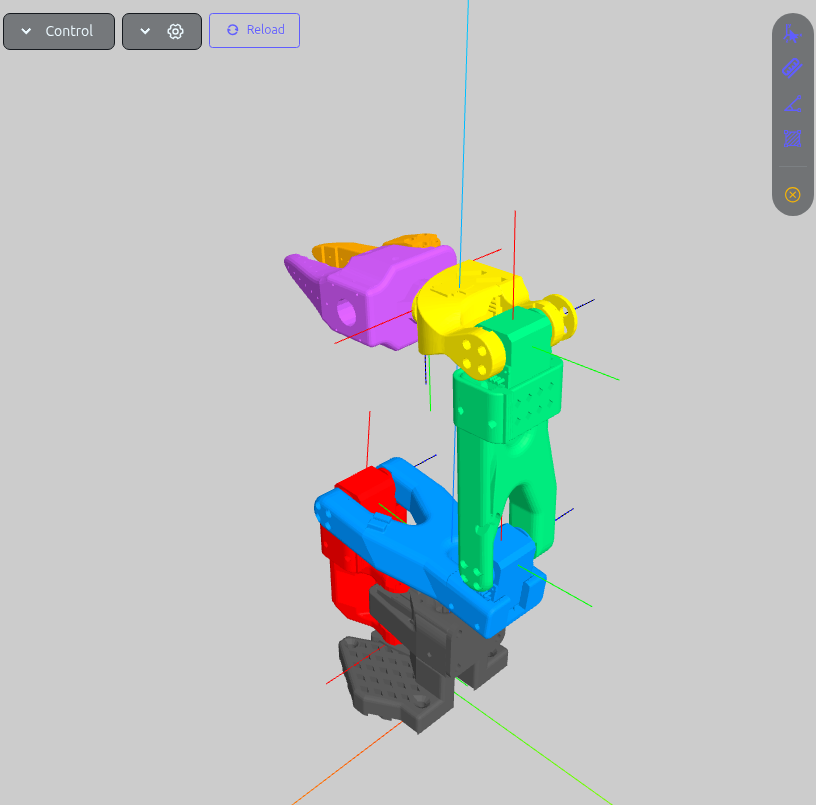

## Análisis de resultados

Responder con base en las decisiones y verificaciones realizadas:

1. ¿Qué diferencias hay entre los sistemas de referencia globales y locales de Blender? ¿Cómo los utilizó para identificar los ejes de los motores?

El sistema de coordenadas global de Blender es una referencia fija para toda la escena, cuyos ejes X, Y y Z permiten conocer la ubicación y orientación de los objetos. Por otro lado, el sistema local es propio de cada pieza, por lo que sus ejes pueden cambiar de orientación dependiendo de las rotaciones aplicadas al objeto.
Durante la práctica se utilizaron ambos sistemas para identificar las posiciones de los componentes del robot SO-100 y analizar la orientación de sus articulaciones. Mediante la visualización de los ejes locales se identificó la dirección de giro de los motores, tomando como referencia el eje Z para configurar las articulaciones en el archivo URDF.
Esto permitió comprender la importancia de establecer correctamente los sistemas de referencia, ya que las posiciones y orientaciones de las piezas influyen directamente en la representación cinemática del robot.

2. ¿Qué efecto tuvo aplicar una rotación a la malla y cómo comprobó que no se alteró la interpretación cinemática de las piezas?

La función Apply Rotation de Blender permite aplicar la rotación actual a la geometría de una pieza, haciendo que sus valores de rotación regresen a cero sin modificar su orientación visual. Sin embargo, esta operación también cambia la relación entre la geometría y sus ejes locales, por lo que debe utilizarse con cuidado al trabajar con articulaciones robóticas.

En el desarrollo del modelo SO-100 fue importante diferenciar la orientación visual de las piezas y la orientación de sus ejes de movimiento. Para ello, en el archivo URDF se utilizaron transformaciones rpy que permitieron ajustar las geometrías STL y definir de manera independiente la orientación de las articulaciones.

La interpretación cinemática puede comprobarse mediante la visualización de los sistemas de referencia y verificando que cada articulación gire alrededor del eje físico correspondiente, sin provocar desplazamientos incorrectos entre las piezas.

3. Explique la diferencia entre la transformación definida en `joint/origin` y la definida en `visual/origin`.

La principal diferencia se encuentra en la función que cumple cada transformación dentro del modelo URDF. La etiqueta joint/origin define la posición (xyz) y orientación (rpy) de una articulación respecto al sistema de referencia del eslabón padre. Esta información es fundamental para establecer la ubicación del punto de unión y la orientación del eje alrededor del cual se realiza el movimiento.

Por otro lado, visual/origin se utiliza para definir la posición y orientación de la geometría visual de una pieza respecto al sistema de referencia de su propio eslabón. Su función es permitir que los modelos STL se visualicen correctamente sin modificar directamente la transformación de la articulación.

En el robot SO-100 se utilizaron ambas transformaciones: joint/origin para establecer las conexiones y los movimientos entre eslabones, y visual/origin para corregir la orientación de algunas piezas importadas desde Blender. Esto permitió representar correctamente la geometría del robot y definir su estructura cinemática.


4. ¿Qué ventajas tiene describir el robot mediante URDF frente a disponer únicamente de un conjunto de modelos STL?

Los archivos STL contienen principalmente información sobre la geometría tridimensional de las piezas, pero no describen cómo se conectan entre sí ni qué movimientos pueden realizar. Por esta razón, disponer únicamente de los modelos STL permite visualizar los componentes individuales, pero no representar completamente el funcionamiento de un robot articulado.

En cambio, el formato URDF permite organizar las piezas mediante eslabones (link) y articulaciones (joint), estableciendo las relaciones padre/hijo, las posiciones, orientaciones, ejes de rotación y límites de movimiento. Además, puede incorporar información adicional, como propiedades de masa, inercia y geometrías de colisión, necesarias para aplicaciones de simulación más avanzadas.

En esta práctica, el uso de URDF permitió integrar los siete eslabones y las seis articulaciones del robot SO-100, obteniendo un modelo ensamblado que se puede visualizar en Visual Studio Code mediante URDF Visualizer. De esta manera, se pasó de tener únicamente piezas tridimensionales a contar con una representación estructurada de la cinemática del robot.

## Conclusiones

En esta práctica se realizó la construcción del modelo URDF del robot SO-100 a partir de sus piezas STL, utilizando Blender para organizar los eslabones, identificar sus sistemas de referencia y establecer las relaciones padre/hijo. Posteriormente, se definieron las articulaciones y sus transformaciones mediante código URDF en Visual Studio Code.

La práctica permitió comprender la importancia de los sistemas de coordenadas locales y globales, así como la diferencia entre las transformaciones de las geometrías y las articulaciones. También se aprendió que no basta con ensamblar visualmente las piezas, sino que es necesario definir correctamente los ejes de giro para representar el movimiento del robot.

Finalmente, se logró desarrollar de manera exitosa el modelo del robot SO-100 en formato URDF, integrando correctamente sus siete eslabones y seis articulaciones. Se obtuvo un modelo funcional que permite visualizar el robot completo y sus sistemas de referencia en Visual Studio Code, cumpliendo con el objetivo de la práctica y reforzando los conocimientos vistos en la teoría.

## Bibliografía

Incluya las fuentes consultadas en formato IEEE, en caso de haberlas consultado.

> [1] Ing. R. Á. García García, Apuntes y material de clase de Robótica: modelado de robots mediante Blender y URDF, Facultad de Ingeniería, Universidad Nacional Autónoma de México (UNAM), México, 2026. Material didáctico de clase.